      Kesit Tipi  Alan (mm²)  Atalet Momenti I (cm⁴)  Kesit Modülü S (cm³)  Max Yük F_max (N)  Dayanım/Ağırlık (F/W)  Max Sehim @F_max (mm)
 Dolu Dikdörtgen      101.01                    0.13                  0.21             497.34                 422.48                   7.54
Kutu Kesit (Box)      101.01                    1.24                  0.82            1976.05                1678.60                   3.07
        I-Profil      101.01                    1.44                  0.90            2160.04                1834.90                   2.90
         C-Kanal      101.01                    0.99                  0.70            1682.94                1429.61                   3.28


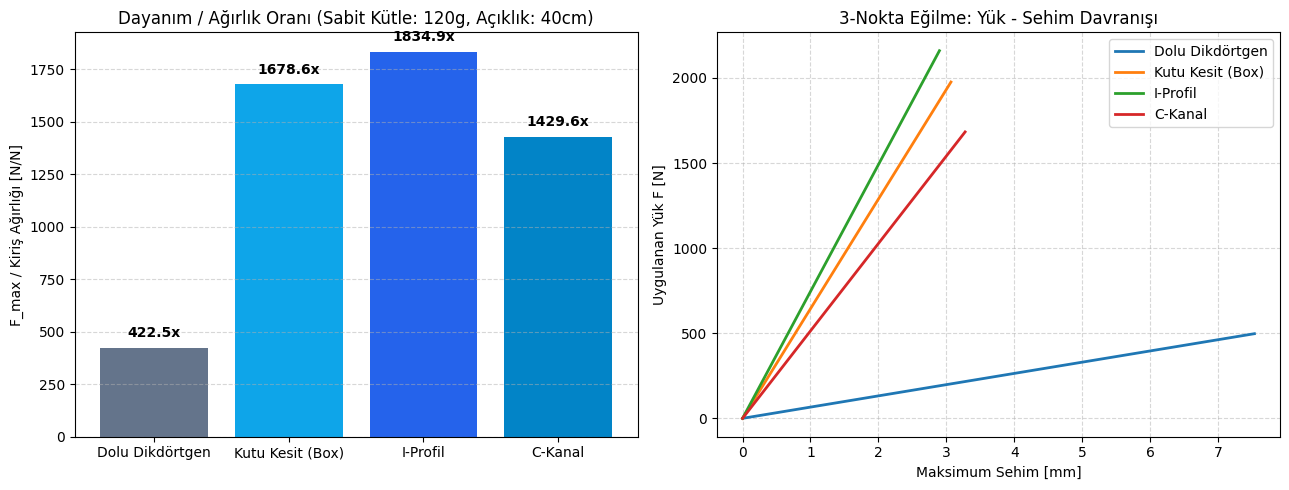

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==========================================
# 1. PARAMETRELER (İhtiyaca göre değiştirilebilir)
# ==========================================
L_span = 0.40        # Mesnetler arası açıklık [m] (400 mm)
L_total = 0.44       # Kiriş toplam boyu [m] (440 mm)
mass = 0.120         # Kiriş malzeme kütlesi [kg] (120 g - tüm profillerde sabit)
rho = 2700.0         # Malzeme yoğunluğu [kg/m^3] (ör. Alüminyum 6061)
sigma_allow = 240e6  # İzin verilen/akma eğilme gerilmesi [Pa] (240 MPa)
E = 69e9             # Elastisite modülü [Pa] (69 GPa)
g = 9.81             # Yerçekimi ivmesi [m/s^2]

# Sabit kesit alanı [m^2] (Aynı kütle ve aynı boy -> Aynı alan)
A_target = mass / (rho * L_total)
weight_N = mass * g

# ==========================================
# 2. KESİT GEOMETRİLERİ & ATALET MOMENTLERİ
#    (Tüm kesitler A_target alanına göre ölçeklenir)
# ==========================================
def calc_sections(A, sigma_max):
    sections = {}

    # 1) Dolu Dikdörtgen (b: genişlik, h: yükseklik; h/b = 1.5 oranı)
    b_rect = np.sqrt(A / 1.5)
    h_rect = 1.5 * b_rect
    I_rect = (b_rect * h_rect**3) / 12.0
    y_rect = h_rect / 2.0
    sections["Dolu Dikdörtgen"] = {
        "A": A, "I": I_rect, "y_max": y_rect,
        "dims": {"b": b_rect, "h": h_rect}
    }

    # 2) İnce Cidarlı Kutu Kesit (Dış yükseklik h = 2.4*h_rect, genişlik b = 0.6*h)
    h_box = 2.4 * h_rect
    b_box = 0.6 * h_box
    # Alan A ≈ 2*t*(b + h - 2*t) -> ikinci dereceden denklemle cidar kalınlığı t
    # Yaklaşık ince cidar: t ≈ A / (2*(b + h))
    t_box = A / (2.0 * (b_box + h_box))
    b_in = max(b_box - 2 * t_box, 1e-6)
    h_in = max(h_box - 2 * t_box, 1e-6)
    A_box_exact = b_box * h_box - b_in * h_in
    # Düzeltme için ölçekleme
    scale_box = np.sqrt(A / A_box_exact)
    b_box, h_box, b_in, h_in = b_box*scale_box, h_box*scale_box, b_in*scale_box, h_in*scale_box
    I_box = (b_box * h_box**3 - b_in * h_in**3) / 12.0
    sections["Kutu Kesit (Box)"] = {
        "A": b_box*h_box - b_in*h_in, "I": I_box, "y_max": h_box / 2.0,
        "dims": {"b": b_box, "h": h_box, "b_in": b_in, "h_in": h_in}
    }

    # 3) I-Profil (Yüksek başlık, ince gövde)
    h_i = 2.6 * h_rect
    b_f = 1.1 * h_rect
    tf = 0.14 * h_rect
    # Gövde alanı: A_web = A - 2*(b_f * tf)
    A_web = max(A - 2.0 * b_f * tf, 0.15 * A)
    h_web = max(h_i - 2.0 * tf, 1e-5)
    tw = A_web / h_web
    # Tam alan dengelemesi
    A_i_exact = 2.0 * b_f * tf + tw * h_web
    scale_i = np.sqrt(A / A_i_exact)
    h_i, b_f, tf, tw = h_i*scale_i, b_f*scale_i, tf*scale_i, tw*scale_i
    h_web = h_i - 2.0 * tf
    I_i = (b_f * h_i**3 - (b_f - tw) * h_web**3) / 12.0
    sections["I-Profil"] = {
        "A": 2.0 * b_f * tf + tw * h_web, "I": I_i, "y_max": h_i / 2.0,
        "dims": {"h": h_i, "bf": b_f, "tf": tf, "tw": tw}
    }

    # 4) C-Kanal Profil (Tek taraflı başlıklar + gövde)
    h_c = 2.3 * h_rect
    b_fc = 0.85 * h_rect
    tfc = 0.15 * h_rect
    A_web_c = max(A - 2.0 * b_fc * tfc, 0.2 * A)
    h_web_c = max(h_c - 2.0 * tfc, 1e-5)
    twc = A_web_c / h_web_c
    A_c_exact = 2.0 * b_fc * tfc + twc * h_web_c
    scale_c = np.sqrt(A / A_c_exact)
    h_c, b_fc, tfc, twc = h_c*scale_c, b_fc*scale_c, tfc*scale_c, twc*scale_c
    h_web_c = h_c - 2.0 * tfc
    # Simetrik yatay eksen etrafında I_x
    I_c = (b_fc * h_c**3 - (b_fc - twc) * h_web_c**3) / 12.0
    sections["C-Kanal"] = {
        "A": 2.0 * b_fc * tfc + twc * h_web_c, "I": I_c, "y_max": h_c / 2.0,
        "dims": {"h": h_c, "bf": b_fc, "tf": tfc, "tw": twc}
    }

    # 3-Nokta Eğilme: M_max = (F_max * L_span) / 4  =>  F_max = (4 * sigma_max * I) / (y_max * L_span)
    rows = []
    for name, data in sections.items():
        S_x = data["I"] / data["y_max"]
        M_max = sigma_max * S_x
        F_max = (4.0 * M_max) / L_span
        # Dayanım / Ağırlık oranı [N / N] (boyutsuz) ve [N / kg]
        stw_ratio_dimless = F_max / weight_N
        stw_ratio_per_kg = F_max / mass
        # F_max yükündeki maksimum sehim [mm]: delta = (F * L^3) / (48 * E * I)
        deflection_mm = ((F_max * L_span**3) / (48.0 * E * data["I"])) * 1000.0

        rows.append({
            "Kesit Tipi": name,
            "Alan (mm²)": data["A"] * 1e6,
            "Atalet Momenti I (cm⁴)": data["I"] * 1e8,
            "Kesit Modülü S (cm³)": S_x * 1e6,
            "Max Eğilme Momenti (N·m)": M_max,
            "Max Yük F_max (N)": F_max,
            "Dayanım/Ağırlık (F/W)": stw_ratio_dimless,
            "Max Sehim @F_max (mm)": deflection_mm,
            "_raw": data
        })

    return pd.DataFrame(rows)

df = calc_sections(A_target, sigma_allow)
display_cols = [
    "Kesit Tipi", "Alan (mm²)", "Atalet Momenti I (cm⁴)",
    "Kesit Modülü S (cm³)", "Max Yük F_max (N)",
    "Dayanım/Ağırlık (F/W)", "Max Sehim @F_max (mm)"
]
print(df[display_cols].to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# ==========================================
# 3. GÖRSELLEŞTİRME: KESİTLER & DAYANIM/AĞIRLIK ORANI
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Sol grafik: Dayanım/Ağırlık Oranı
bars = axes[0].bar(df["Kesit Tipi"], df["Dayanım/Ağırlık (F/W)"], color=["#64748b", "#0ea5e9", "#2563eb", "#0284c7"])
axes[0].set_title(f"Dayanım / Ağırlık Oranı (Sabit Kütle: {mass*1000:.0f}g, Açıklık: {L_span*100:.0f}cm)")
axes[0].set_ylabel("F_max / Kiriş Ağırlığı [N/N]")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars:
    h_val = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h_val + max(df["Dayanım/Ağırlık (F/W)"])*0.02,
                 f"{h_val:.1f}x", ha="center", va="bottom", fontweight="bold")

# Sağ grafik: Yük - Sehim Eğrileri (0 -> F_max)
for _, row in df.iterrows():
    I_val = row["_raw"]["I"]
    F_max_val = row["Max Yük F_max (N)"]
    F_vec = np.linspace(0, F_max_val, 100)
    delta_mm = ((F_vec * L_span**3) / (48.0 * E * I_val)) * 1000.0
    axes[1].plot(delta_mm, F_vec, label=row["Kesit Tipi"], linewidth=2)

axes[1].set_title("3-Nokta Eğilme: Yük - Sehim Davranışı")
axes[1].set_xlabel("Maksimum Sehim [mm]")
axes[1].set_ylabel("Uygulanan Yük F [N]")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, clear_output

# ==========================================
# 1. MATERIAL DATABASE (SI Units)
# ==========================================
MATERIALS = {
    "Aluminum 6061-T6": {"rho": 2700.0, "sigma_y": 276e6, "E": 68.9e9},
    "Structural Steel (A36)": {"rho": 7850.0, "sigma_y": 250e6, "E": 200e9},
    "Carbon Fiber Composite (UD)": {"rho": 1600.0, "sigma_y": 600e6, "E": 135e9},
    "Balsa Wood (Medium)": {"rho": 160.0, "sigma_y": 15e6, "E": 3.5e9},
    "PLA (3D Print)": {"rho": 1240.0, "sigma_y": 50e6, "E": 3.5e9},
}

ALL_SECTIONS = [
    "Solid Rectangle",
    "Hollow Box",
    "I-Beam",
    "C-Channel",
]

# ==========================================
# 2. SECTION GEOMETRY & BENDING SOLVER
# ==========================================
def compute_section_metrics(sec_name, A_target, L_span, mat_props, load_method, safety_factor):
    rho = mat_props["rho"]
    sigma_allow = mat_props["sigma_y"] / safety_factor
    E = mat_props["E"]

    # Base reference rectangle height/width ratio (h / b = 1.5)
    b_ref = np.sqrt(A_target / 1.5)
    h_ref = 1.5 * b_ref

    if sec_name == "Solid Rectangle":
        b, h = b_ref, h_ref
        I = (b * h**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "rect", "b": b, "h": h}

    elif sec_name == "Hollow Box":
        h = 2.3 * h_ref
        b = 0.65 * h
        t_est = max(A_target / (2.0 * (b + h)), 1e-5)
        b_in = max(b - 2.0 * t_est, 1e-6)
        h_in = max(h - 2.0 * t_est, 1e-6)
        A_raw = max(b * h - b_in * h_in, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        b, h, b_in, h_in = b * scale, h * scale, b_in * scale, h_in * scale
        I = (b * h**3 - b_in * h_in**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "box", "b": b, "h": h, "b_in": b_in, "h_in": h_in}

    elif sec_name == "I-Beam":
        h = 2.5 * h_ref
        bf = 1.15 * h_ref
        tf = 0.14 * h_ref
        A_flange_tot = 2.0 * bf * tf
        if A_flange_tot >= 0.85 * A_target:
            tf = (0.40 * A_target) / max(bf, 1e-6)
        h_web = max(h - 2.0 * tf, 1e-5)
        tw = max((A_target - 2.0 * bf * tf) / h_web, 1e-6)
        A_raw = max(2.0 * bf * tf + tw * h_web, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        h, bf, tf, tw = h * scale, bf * scale, tf * scale, tw * scale
        h_web = max(h - 2.0 * tf, 1e-6)
        I = (bf * h**3 - (bf - tw) * h_web**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "ibeam", "h": h, "bf": bf, "tf": tf, "tw": tw}

    elif sec_name == "C-Channel":
        h = 2.2 * h_ref
        bf = 0.85 * h_ref
        tf = 0.15 * h_ref
        if 2.0 * bf * tf >= 0.85 * A_target:
            tf = (0.40 * A_target) / max(bf, 1e-6)
        h_web = max(h - 2.0 * tf, 1e-5)
        tw = max((A_target - 2.0 * bf * tf) / h_web, 1e-6)
        A_raw = max(2.0 * bf * tf + tw * h_web, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        h, bf, tf, tw = h * scale, bf * scale, tf * scale, tw * scale
        h_web = max(h - 2.0 * tf, 1e-6)
        I = (bf * h**3 - (bf - tw) * h_web**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "cchannel", "h": h, "bf": bf, "tf": tf, "tw": tw}

    S_x = I / y_max
    M_max = sigma_allow * S_x  # Max allowable bending moment [N*m]

    # Load method relations:
    # 1) 3-Point Bending (center load F): M_max = F * L / 4  => F_max = 4 * M_max / L
    #    Deflection: delta = F * L^3 / (48 * E * I)
    # 2) 4-Point Bending (two loads F/2 at L/3 from supports): M_max = (F/2) * (L/3) = F * L / 6 => F_max = 6 * M_max / L
    #    Deflection (midspan): delta = (23 * F * L^3) / (648 * E * I)
    # 3) Cantilever Tip Load (load F at free end L): M_max = F * L => F_max = M_max / L
    #    Deflection (tip): delta = F * L^3 / (3 * E * I)
    if load_method == "3-Point Bending (Center Load)":
        F_max = (4.0 * M_max) / L_span
        defl_coeff = 1.0 / 48.0
    elif load_method == "4-Point Bending (L/3 Loads)":
        F_max = (6.0 * M_max) / L_span
        defl_coeff = 23.0 / 648.0
    else:  # "Cantilever (Tip Load)"
        F_max = M_max / L_span
        defl_coeff = 1.0 / 3.0

    max_defl_mm = ((F_max * (L_span**3) * defl_coeff) / max(E * I, 1e-12)) * 1000.0
    # Specific strength / strength-to-weight metrics:
    # 1) Dimensionless load-to-weight ratio: F_max / W_beam
    # 2) Specific load capacity [N/kg]: F_max / mass_beam
    return {
        "Section": sec_name,
        "I_cm4": I * 1e8,
        "S_cm3": S_x * 1e6,
        "M_max_Nm": M_max,
        "F_max_N": F_max,
        "Max_Defl_mm": max_defl_mm,
        "I_raw": I,
        "defl_coeff": defl_coeff,
        "geom": geom,
    }

def draw_cross_section(ax, geom, title):
    ax.clear()
    gtype = geom["type"]
    color_fill = "#2563eb"

    if gtype == "rect":
        b, h = geom["b"] * 1e3, geom["h"] * 1e3
        rect = patches.Rectangle((-b/2, -h/2), b, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.5)
        ax.add_patch(rect)
        lim = max(b, h) * 0.75

    elif gtype == "box":
        b, h = geom["b"] * 1e3, geom["h"] * 1e3
        bi, hi = geom["b_in"] * 1e3, geom["h_in"] * 1e3
        outer = patches.Rectangle((-b/2, -h/2), b, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.5)
        inner = patches.Rectangle((-bi/2, -hi/2), bi, hi, facecolor="white", edgecolor="#0f172a", lw=1.2)
        ax.add_patch(outer)
        ax.add_patch(inner)
        lim = max(b, h) * 0.75

    elif gtype == "ibeam":
        h, bf = geom["h"] * 1e3, geom["bf"] * 1e3
        tf, tw = geom["tf"] * 1e3, geom["tw"] * 1e3
        # Top flange, web, bottom flange
        p1 = patches.Rectangle((-bf/2, h/2 - tf), bf, tf, facecolor=color_fill, edgecolor="#0f172a", lw=1.2)
        p2 = patches.Rectangle((-tw/2, -h/2 + tf), tw, h - 2*tf, facecolor=color_fill, edgecolor="#0f172a", lw=1.2)
        p3 = patches.Rectangle((-bf/2, -h/2), bf, tf, facecolor=color_fill, edgecolor="#0f172a", lw=1.2)
        for p in (p1, p2, p3):
            ax.add_patch(p)
        lim = max(bf, h) * 0.75

    elif gtype == "cchannel":
        h, bf = geom["h"] * 1e3, geom["bf"] * 1e3
        tf, tw = geom["tf"] * 1e3, geom["tw"] * 1e3
        # Web on left (-bf/2), flanges extending right
        p1 = patches.Rectangle((-bf/2, -h/2), tw, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.2)
        p2 = patches.Rectangle((-bf/2 + tw, h/2 - tf), bf - tw, tf, facecolor=color_fill, edgecolor="#0f172a", lw=1.2)
        p3 = patches.Rectangle((-bf/2 + tw, -h/2), bf - tw, tf, facecolor=color_fill, edgecolor="#0f172a", lw=1.2)
        for p in (p1, p2, p3):
            ax.add_patch(p)
        lim = max(bf, h) * 0.75

    ax.axhline(0, color="#dc2626", linestyle="--", linewidth=0.9, alpha=0.7, label="Neutral Axis")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("x [mm]", fontsize=8)
    ax.set_ylabel("y [mm]", fontsize=8)
    ax.set_title(title, fontsize=9, fontweight="bold")
    ax.tick_params(labelsize=7)
    ax.grid(True, linestyle=":", alpha=0.4)

# ==========================================
# 3. INTERACTIVE WIDGETS (ENGLISH UI)
# ==========================================
style = {"description_width": "145px"}
layout_w = widgets.Layout(width="360px")

material_dd = widgets.Dropdown(
    options=list(MATERIALS.keys()),
    value="Aluminum 6061-T6",
    description="Material:",
    style=style, layout=layout_w
)

load_method_dd = widgets.Dropdown(
    options=[
        "3-Point Bending (Center Load)",
        "4-Point Bending (L/3 Loads)",
        "Cantilever (Tip Load)"
    ],
    value="3-Point Bending (Center Load)",
    description="Load Method:",
    style=style, layout=layout_w
)

span_slider = widgets.FloatSlider(
    value=0.40, min=0.10, max=1.50, step=0.05,
    description="Span Length [m]:",
    readout_format=".2f", style=style, layout=layout_w
)

mass_slider = widgets.FloatSlider(
    value=0.150, min=0.020, max=2.000, step=0.010,
    description="Beam Mass [kg]:",
    readout_format=".3f", style=style, layout=layout_w
)

sf_slider = widgets.FloatSlider(
    value=1.5, min=1.0, max=4.0, step=0.1,
    description="Safety Factor:",
    readout_format=".1f", style=style, layout=layout_w
)

metric_dd = widgets.Dropdown(
    options=[
        "Strength-to-Weight Ratio (F_max / Weight [N/N])",
        "Specific Strength (F_max / Mass [N/kg])",
        "Max Allowable Load (F_max [N])"
    ],
    value="Strength-to-Weight Ratio (F_max / Weight [N/N])",
    description="Comparison Metric:",
    style=style, layout=layout_w
)

section_checks = [
    widgets.Checkbox(value=True, description=s, layout=widgets.Layout(width="175px"))
    for s in ALL_SECTIONS
]
sections_box = widgets.VBox([
    widgets.Label("Select Cross-Sections to Compare:", layout=widgets.Layout(font_weight="bold")),
    widgets.HBox(section_checks[:2]),
    widgets.HBox(section_checks[2:]),
])

output_area = widgets.Output()

def update_dashboard(*args):
    with output_area:
        clear_output(wait=True)

        selected = [cb.description for cb in section_checks if cb.value]
        if not selected:
            print("Please select at least one cross-section to compare.")
            return

        mat_name = material_dd.value
        mat_props = MATERIALS[mat_name]
        L_span = span_slider.value
        mass_kg = mass_slider.value
        sf = sf_slider.value
        load_method = load_method_dd.value
        metric = metric_dd.value

        # Equal mass & equal span -> equal cross-sectional area A = m / (rho * L)
        A_target = mass_kg / (mat_props["rho"] * L_span)
        weight_N = mass_kg * 9.81

        results = [
            compute_section_metrics(s, A_target, L_span, mat_props, load_method, sf)
            for s in selected
        ]
        df = pd.DataFrame(results)
        df["STW_Ratio"] = df["F_max_N"] / weight_N
        df["Specific_Strength_N_per_kg"] = df["F_max_N"] / mass_kg

        # Summary table
        table_df = pd.DataFrame({
            "Section": df["Section"],
            "I_x [cm^4]": df["I_cm4"].round(3),
            "S_x [cm^3]": df["S_cm3"].round(3),
            "Max Load F_max [N]": df["F_max_N"].round(1),
            "STW Ratio [N/N]": df["STW_Ratio"].round(1),
            "Specific Str [N/kg]": df["Specific_Strength_N_per_kg"].round(1),
            "Defl @ F_max [mm]": df["Max_Defl_mm"].round(2),
        })
        print(f"Constant Parameters -> Material: {mat_name} | Span: {L_span:.2f} m | Mass: {mass_kg*1000:.1f} g | Area: {A_target*1e6:.2f} mm^2")
        display(table_df.to_string(index=False))

        # Figure 1: Main Comparison Bar Chart + Load-Deflection Curves
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

        if "STW Ratio" in metric:
            y_vals = df["STW_Ratio"]
            y_label = "Strength-to-Weight Ratio (F_max / Weight) [N/N]"
            chart_title = "Strength-to-Weight Ratio Comparison"
        elif "Specific Strength" in metric:
            y_vals = df["Specific_Strength_N_per_kg"]
            y_label = "Specific Load Capacity (F_max / Mass) [N/kg]"
            chart_title = "Specific Strength Comparison"
        else:
            y_vals = df["F_max_N"]
            y_label = "Max Allowable Load F_max [N]"
            chart_title = "Max Allowable Load Comparison"

        palette = ["#1d4ed8", "#0284c7", "#0d9488", "#4f46e5"]
        bars = ax1.bar(df["Section"], y_vals, color=palette[:len(df)], edgecolor="#0f172a", alpha=0.9)
        ax1.set_title(chart_title, fontsize=11, fontweight="bold")
        ax1.set_ylabel(y_label, fontsize=9)
        ax1.grid(axis="y", linestyle="--", alpha=0.5)
        ax1.tick_params(axis="x", rotation=12, labelsize=9)

        max_y = max(y_vals) if len(y_vals) > 0 else 1.0
        for bar, val in zip(bars, y_vals):
            ax1.text(
                bar.get_x() + bar.get_width() / 2.0,
                val + max_y * 0.02,
                f"{val:.1f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold"
            )

        # Load vs Deflection curves
        for idx, row in df.iterrows():
            f_vec = np.linspace(0, row["F_max_N"], 100)
            defl_vec = ((f_vec * (L_span**3) * row["defl_coeff"]) / max(mat_props["E"] * row["I_raw"], 1e-12)) * 1000.0
            ax2.plot(defl_vec, f_vec, label=row["Section"], linewidth=2.2, color=palette[idx % len(palette)])

        ax2.set_title(f"Load vs. Deflection ({load_method})", fontsize=11, fontweight="bold")
        ax2.set_xlabel("Deflection [mm]", fontsize=9)
        ax2.set_ylabel("Applied Load F [N]", fontsize=9)
        ax2.legend(fontsize=8)
        ax2.grid(True, linestyle="--", alpha=0.5)

        plt.tight_layout()
        plt.show()

        # Figure 2: Scaled Cross-Section Geometries
        n_sec = len(df)
        fig_cs, axes_cs = plt.subplots(1, n_sec, figsize=(3.3 * n_sec, 3.0))
        if n_sec == 1:
            axes_cs = [axes_cs]
        for ax_c, (_, row) in zip(axes_cs, df.iterrows()):
            draw_cross_section(ax_c, row["geom"], f"{row['Section']}\n(I={row['I_cm4']:.2f} cm⁴)")
        plt.tight_layout()
        plt.show()

# Attach observers
for w in [material_dd, load_method_dd, span_slider, mass_slider, sf_slider, metric_dd] + section_checks:
    w.observe(update_dashboard, names="value")

controls_ui = widgets.VBox([
    widgets.HTML("<h3 style='margin-bottom:6px;'>Beam Strength-to-Weight Interactive Analyzer</h3>"),
    widgets.HBox([
        widgets.VBox([material_dd, load_method_dd, metric_dd]),
        widgets.VBox([span_slider, mass_slider, sf_slider]),
        sections_box
    ])
])

display(controls_ui, output_area)
update_dashboard()

Output()

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# ==========================================
# 1. MATERIAL DATABASE & SECTION COLORS
# ==========================================
MATERIALS = {
    "Aluminum 6061-T6": {"rho": 2700.0, "sigma_y": 276e6, "E": 68.9e9},
    "Structural Steel (A36)": {"rho": 7850.0, "sigma_y": 250e6, "E": 200e9},
    "Carbon Fiber Composite (UD)": {"rho": 1600.0, "sigma_y": 600e6, "E": 135e9},
    "Balsa Wood (Medium)": {"rho": 160.0, "sigma_y": 15e6, "E": 3.5e9},
    "PLA (3D Print)": {"rho": 1240.0, "sigma_y": 50e6, "E": 3.5e9},
}

SECTION_COLORS = {
    "Solid Rectangle": "#3b82f6",  # Blue
    "Hollow Box":      "#10b981",  # Emerald Green
    "I-Beam":          "#f97316",  # Orange
    "C-Channel":       "#a855f7",  # Purple
}

ALL_SECTIONS = list(SECTION_COLORS.keys())

# ==========================================
# 2. SECTION GEOMETRY & BENDING SOLVER
# ==========================================
def compute_section_metrics(sec_name, A_target, L_span, mat_props, load_method, safety_factor):
    sigma_allow = mat_props["sigma_y"] / safety_factor
    E = mat_props["E"]

    b_ref = np.sqrt(A_target / 1.5)
    h_ref = 1.5 * b_ref

    if sec_name == "Solid Rectangle":
        b, h = b_ref, h_ref
        I = (b * h**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "rect", "b": b, "h": h}

    elif sec_name == "Hollow Box":
        h = 2.3 * h_ref
        b = 0.65 * h
        t_est = max(A_target / (2.0 * (b + h)), 1e-5)
        b_in = max(b - 2.0 * t_est, 1e-6)
        h_in = max(h - 2.0 * t_est, 1e-6)
        A_raw = max(b * h - b_in * h_in, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        b, h, b_in, h_in = b * scale, h * scale, b_in * scale, h_in * scale
        I = (b * h**3 - b_in * h_in**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "box", "b": b, "h": h, "b_in": b_in, "h_in": h_in}

    elif sec_name == "I-Beam":
        h = 2.5 * h_ref
        bf = 1.15 * h_ref
        tf = 0.14 * h_ref
        if 2.0 * bf * tf >= 0.85 * A_target:
            tf = (0.40 * A_target) / max(bf, 1e-6)
        h_web = max(h - 2.0 * tf, 1e-5)
        tw = max((A_target - 2.0 * bf * tf) / h_web, 1e-6)
        A_raw = max(2.0 * bf * tf + tw * h_web, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        h, bf, tf, tw = h * scale, bf * scale, tf * scale, tw * scale
        h_web = max(h - 2.0 * tf, 1e-6)
        I = (bf * h**3 - (bf - tw) * h_web**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "ibeam", "h": h, "bf": bf, "tf": tf, "tw": tw}

    elif sec_name == "C-Channel":
        h = 2.2 * h_ref
        bf = 0.85 * h_ref
        tf = 0.15 * h_ref
        if 2.0 * bf * tf >= 0.85 * A_target:
            tf = (0.40 * A_target) / max(bf, 1e-6)
        h_web = max(h - 2.0 * tf, 1e-5)
        tw = max((A_target - 2.0 * bf * tf) / h_web, 1e-6)
        A_raw = max(2.0 * bf * tf + tw * h_web, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        h, bf, tf, tw = h * scale, bf * scale, tf * scale, tw * scale
        h_web = max(h - 2.0 * tf, 1e-6)
        I = (bf * h**3 - (bf - tw) * h_web**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "cchannel", "h": h, "bf": bf, "tf": tf, "tw": tw}

    S_x = I / y_max
    M_max = sigma_allow * S_x

    if load_method == "3-Point Bending (Center Load)":
        F_max = (4.0 * M_max) / L_span
        defl_coeff = 1.0 / 48.0
    elif load_method == "4-Point Bending (L/3 Loads)":
        F_max = (6.0 * M_max) / L_span
        defl_coeff = 23.0 / 648.0
    else:  # "Cantilever (Tip Load)"
        F_max = M_max / L_span
        defl_coeff = 1.0 / 3.0

    max_defl_mm = ((F_max * (L_span**3) * defl_coeff) / max(E * I, 1e-12)) * 1000.0

    return {
        "Section": sec_name,
        "Color": SECTION_COLORS[sec_name],
        "I_cm4": I * 1e8,
        "S_cm3": S_x * 1e6,
        "M_max_Nm": M_max,
        "F_max_N": F_max,
        "Max_Defl_mm": max_defl_mm,
        "I_raw": I,
        "defl_coeff": defl_coeff,
        "geom": geom,
    }

def draw_cross_section(ax, geom, color_fill, title):
    ax.clear()
    gtype = geom["type"]

    if gtype == "rect":
        b, h = geom["b"] * 1e3, geom["h"] * 1e3
        rect = patches.Rectangle((-b/2, -h/2), b, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.5, alpha=0.92)
        ax.add_patch(rect)
        lim = max(b, h) * 0.75

    elif gtype == "box":
        b, h = geom["b"] * 1e3, geom["h"] * 1e3
        bi, hi = geom["b_in"] * 1e3, geom["h_in"] * 1e3
        outer = patches.Rectangle((-b/2, -h/2), b, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.5, alpha=0.92)
        inner = patches.Rectangle((-bi/2, -hi/2), bi, hi, facecolor="white", edgecolor="#0f172a", lw=1.2)
        ax.add_patch(outer)
        ax.add_patch(inner)
        lim = max(b, h) * 0.75

    elif gtype == "ibeam":
        h, bf = geom["h"] * 1e3, geom["bf"] * 1e3
        tf, tw = geom["tf"] * 1e3, geom["tw"] * 1e3
        for x0, y0, w, ht in [
            (-bf/2, h/2 - tf, bf, tf),
            (-tw/2, -h/2 + tf, tw, h - 2*tf),
            (-bf/2, -h/2, bf, tf),
        ]:
            ax.add_patch(patches.Rectangle((x0, y0), w, ht, facecolor=color_fill, edgecolor="#0f172a", lw=1.2, alpha=0.92))
        lim = max(bf, h) * 0.75

    elif gtype == "cchannel":
        h, bf = geom["h"] * 1e3, geom["bf"] * 1e3
        tf, tw = geom["tf"] * 1e3, geom["tw"] * 1e3
        for x0, y0, w, ht in [
            (-bf/2, -h/2, tw, h),
            (-bf/2 + tw, h/2 - tf, bf - tw, tf),
            (-bf/2 + tw, -h/2, bf - tw, tf),
        ]:
            ax.add_patch(patches.Rectangle((x0, y0), w, ht, facecolor=color_fill, edgecolor="#0f172a", lw=1.2, alpha=0.92))
        lim = max(bf, h) * 0.75

    ax.axhline(0, color="#ef4444", linestyle="--", linewidth=1.0, alpha=0.85, label="Neutral Axis")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("x [mm]", fontsize=8.5)
    ax.set_ylabel("y [mm]", fontsize=8.5)
    ax.set_title(title, fontsize=9.5, fontweight="bold", color=color_fill, pad=8)
    ax.tick_params(labelsize=7.5)
    ax.grid(True, linestyle=":", alpha=0.45)

# ==========================================
# 3. STYLED INTERACTIVE WIDGETS (ENGLISH UI)
# ==========================================
style = {"description_width": "135px"}
layout_w = widgets.Layout(width="340px")

material_dd = widgets.Dropdown(
    options=list(MATERIALS.keys()),
    value="Aluminum 6061-T6",
    description="Material:",
    style=style, layout=layout_w
)

load_method_dd = widgets.Dropdown(
    options=[
        "3-Point Bending (Center Load)",
        "4-Point Bending (L/3 Loads)",
        "Cantilever (Tip Load)"
    ],
    value="3-Point Bending (Center Load)",
    description="Load Method:",
    style=style, layout=layout_w
)

metric_dd = widgets.Dropdown(
    options=[
        "Strength-to-Weight Ratio (F_max / Weight [N/N])",
        "Specific Strength (F_max / Mass [N/kg])",
        "Max Allowable Load (F_max [N])"
    ],
    value="Strength-to-Weight Ratio (F_max / Weight [N/N])",
    description="Metric:",
    style=style, layout=layout_w
)

span_slider = widgets.FloatSlider(
    value=0.40, min=0.10, max=1.50, step=0.05,
    description="Span Length [m]:",
    readout_format=".2f", style=style, layout=layout_w
)

mass_slider = widgets.FloatSlider(
    value=0.150, min=0.020, max=2.000, step=0.010,
    description="Beam Mass [kg]:",
    readout_format=".3f", style=style, layout=layout_w
)

sf_slider = widgets.FloatSlider(
    value=1.5, min=1.0, max=4.0, step=0.1,
    description="Safety Factor:",
    readout_format=".1f", style=style, layout=layout_w
)

section_checks = []
for s in ALL_SECTIONS:
    c_hex = SECTION_COLORS[s]
    cb = widgets.Checkbox(value=True, description=s, layout=widgets.Layout(width="165px"))
    swatch = widgets.HTML(
        f"<span style='display:inline-block;width:12px;height:12px;border-radius:3px;"
        f"background:{c_hex};border:1px solid #1e293b;margin-top:4px;'></span>"
    )
    section_checks.append((cb, swatch))

sections_box = widgets.VBox([
    widgets.HTML("<div style='font-weight:600;color:#e2e8f0;margin-bottom:6px;'>Cross-Sections to Compare:</div>"),
    widgets.HBox([widgets.HBox([section_checks[0][0], section_checks[0][1]]),
                  widgets.HBox([section_checks[1][0], section_checks[1][1]])]),
    widgets.HBox([widgets.HBox([section_checks[2][0], section_checks[2][1]]),
                  widgets.HBox([section_checks[3][0], section_checks[3][1]])]),
], layout=widgets.Layout(
    padding="10px 14px",
    border="1px solid #334155",
    border_radius="8px",
    background_color="#1e293b"
))

output_area = widgets.Output()

def render_param_banner(mat_name, mat_props, L_span, mass_kg, sf, A_target, load_method):
    sigma_allow_mpa = (mat_props["sigma_y"] / sf) / 1e6
    e_gpa = mat_props["E"] / 1e9
    html = f"""
    <div style="
        background: linear-gradient(135deg, #0f172a 0%, #1e293b 100%);
        border: 1px solid #334155;
        border-left: 4px solid #38bdf8;
        border-radius: 8px;
        padding: 12px 16px;
        margin: 8px 0 12px 0;
        color: #f8fafc;
        font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
    ">
        <div style="font-size:11px;text-transform:uppercase;letter-spacing:0.8px;color:#94a3b8;margin-bottom:8px;">
            Constant Design &amp; Test Conditions
        </div>
        <div style="display:flex;flex-wrap:wrap;gap:18px;font-size:13px;">
            <div><span style="color:#94a3b8;">Material:</span> <b>{mat_name}</b></div>
            <div><span style="color:#94a3b8;">Span:</span> <b>{L_span:.2f} m</b></div>
            <div><span style="color:#94a3b8;">Mass:</span> <b>{mass_kg*1000:.1f} g</b> ({mass_kg:.3f} kg)</div>
            <div><span style="color:#94a3b8;">Cross-Section Area:</span> <b>{A_target*1e6:.2f} mm²</b></div>
            <div><span style="color:#94a3b8;">Allowable Stress:</span> <b>{sigma_allow_mpa:.1f} MPa</b> (SF={sf:.1f})</div>
            <div><span style="color:#94a3b8;">Elastic Modulus E:</span> <b>{e_gpa:.1f} GPa</b></div>
            <div><span style="color:#94a3b8;">Load:</span> <b>{load_method}</b></div>
        </div>
    </div>
    """
    display(HTML(html))

def update_dashboard(*args):
    with output_area:
        clear_output(wait=True)

        selected = [cb.description for cb, _ in section_checks if cb.value]
        if not selected:
            display(HTML("<div style='color:#f87171;padding:10px;'>Please select at least one cross-section to compare.</div>"))
            return

        mat_name = material_dd.value
        mat_props = MATERIALS[mat_name]
        L_span = span_slider.value
        mass_kg = mass_slider.value
        sf = sf_slider.value
        load_method = load_method_dd.value
        metric = metric_dd.value

        A_target = mass_kg / (mat_props["rho"] * L_span)
        weight_N = mass_kg * 9.81

        render_param_banner(mat_name, mat_props, L_span, mass_kg, sf, A_target, load_method)

        results = [
            compute_section_metrics(s, A_target, L_span, mat_props, load_method, sf)
            for s in selected
        ]
        df = pd.DataFrame(results)
        df["STW_Ratio"] = df["F_max_N"] / weight_N
        df["Specific_Strength_N_per_kg"] = df["F_max_N"] / mass_kg

        table_df = pd.DataFrame({
            "Section": df["Section"],
            "I_x [cm^4]": df["I_cm4"].round(3),
            "S_x [cm^3]": df["S_cm3"].round(3),
            "Max Load F_max [N]": df["F_max_N"].round(1),
            "STW Ratio [N/N]": df["STW_Ratio"].round(1),
            "Specific Str [N/kg]": df["Specific_Strength_N_per_kg"].round(1),
            "Defl @ F_max [mm]": df["Max_Defl_mm"].round(2),
        })
        display(table_df.style.hide(axis="index").format({
            "I_x [cm^4]": "{:.3f}",
            "S_x [cm^3]": "{:.3f}",
            "Max Load F_max [N]": "{:.1f}",
            "STW Ratio [N/N]": "{:.1f}",
            "Specific Str [N/kg]": "{:.1f}",
            "Defl @ F_max [mm]": "{:.2f}",
        }))

        # Figure 1: Bar Chart + Load vs Deflection
        plt.style.use("seaborn-v0_8-whitegrid")
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.6))

        if "STW Ratio" in metric:
            y_vals = df["STW_Ratio"]
            y_label = "Strength-to-Weight Ratio (F_max / Weight) [N/N]"
            chart_title = "Strength-to-Weight Ratio Comparison"
        elif "Specific Strength" in metric:
            y_vals = df["Specific_Strength_N_per_kg"]
            y_label = "Specific Load Capacity (F_max / Mass) [N/kg]"
            chart_title = "Specific Strength Comparison"
        else:
            y_vals = df["F_max_N"]
            y_label = "Max Allowable Load F_max [N]"
            chart_title = "Max Allowable Load Comparison"

        colors = df["Color"].tolist()
        bars = ax1.bar(df["Section"], y_vals, color=colors, edgecolor="#0f172a", linewidth=1.1, alpha=0.92, width=0.55)
        ax1.set_title(chart_title, fontsize=11.5, fontweight="bold", pad=10)
        ax1.set_ylabel(y_label, fontsize=9.5)
        ax1.tick_params(axis="x", rotation=10, labelsize=9.5)

        max_y = max(y_vals) if len(y_vals) > 0 else 1.0
        ax1.set_ylim(0, max_y * 1.15)
        for bar, val, col in zip(bars, y_vals, colors):
            ax1.text(
                bar.get_x() + bar.get_width() / 2.0,
                val + max_y * 0.02,
                f"{val:.1f}",
                ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#0f172a"
            )

        for _, row in df.iterrows():
            f_vec = np.linspace(0, row["F_max_N"], 100)
            defl_vec = ((f_vec * (L_span**3) * row["defl_coeff"]) / max(mat_props["E"] * row["I_raw"], 1e-12)) * 1000.0
            ax2.plot(defl_vec, f_vec, label=row["Section"], linewidth=2.4, color=row["Color"])

        ax2.set_title(f"Load vs. Deflection ({load_method})", fontsize=11.5, fontweight="bold", pad=10)
        ax2.set_xlabel("Deflection [mm]", fontsize=9.5)
        ax2.set_ylabel("Applied Load F [N]", fontsize=9.5)
        ax2.legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", fontsize=9)

        plt.tight_layout()
        plt.show()

        # Figure 2: Matched-Color Cross-Section Geometries
        n_sec = len(df)
        fig_cs, axes_cs = plt.subplots(1, n_sec, figsize=(3.4 * n_sec, 3.1))
        if n_sec == 1:
            axes_cs = [axes_cs]
        for ax_c, (_, row) in zip(axes_cs, df.iterrows()):
            draw_cross_section(
                ax_c,
                row["geom"],
                row["Color"],
                f"{row['Section']}\n(I = {row['I_cm4']:.2f} cm⁴)"
            )
        plt.tight_layout()
        plt.show()

all_inputs = [material_dd, load_method_dd, metric_dd, span_slider, mass_slider, sf_slider] + [cb for cb, _ in section_checks]
for w in all_inputs:
    w.observe(update_dashboard, names="value")

controls_ui = widgets.VBox([
    widgets.HTML("""
        <div style="padding:10px 14px;background:#0f172a;border-radius:8px;border:1px solid #334155;margin-bottom:8px;">
            <div style="font-size:17px;font-weight:700;color:#f8fafc;">Beam Strength-to-Weight Interactive Analyzer</div>
            <div style="font-size:12px;color:#94a3b8;">Equal span, equal mass, and matched cross-section color coding</div>
        </div>
    """),
    widgets.HBox([
        widgets.VBox([material_dd, load_method_dd, metric_dd], layout=widgets.Layout(margin="0 12px 0 0")),
        widgets.VBox([span_slider, mass_slider, sf_slider], layout=widgets.Layout(margin="0 12px 0 0")),
        sections_box
    ], layout=widgets.Layout(align_items="flex-start"))
])

display(controls_ui, output_area)
update_dashboard()

Output()

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# ==========================================
# 1. MATERIAL DATABASE & SECTION COLORS
# ==========================================
MATERIALS = {
    "Aluminum 6061-T6": {"rho": 2700.0, "sigma_y": 276e6, "E": 68.9e9},
    "Structural Steel (A36)": {"rho": 7850.0, "sigma_y": 250e6, "E": 200e9},
    "Carbon Fiber Composite (UD)": {"rho": 1600.0, "sigma_y": 600e6, "E": 135e9},
    "Balsa Wood (Medium)": {"rho": 160.0, "sigma_y": 15e6, "E": 3.5e9},
    "PLA (3D Print)": {"rho": 1240.0, "sigma_y": 50e6, "E": 3.5e9},
}

SECTION_COLORS = {
    "Solid Rectangle": "#3b82f6",  # Blue
    "Hollow Box":      "#10b981",  # Emerald Green
    "I-Beam":          "#f97316",  # Orange
    "C-Channel":       "#a855f7",  # Purple
}

ALL_SECTIONS = list(SECTION_COLORS.keys())

# ==========================================
# 2. SECTION GEOMETRY & BENDING SOLVER
# ==========================================
def compute_section_metrics(sec_name, A_target, L_span, mat_props, load_method, safety_factor):
    sigma_allow = mat_props["sigma_y"] / safety_factor
    E = mat_props["E"]

    b_ref = np.sqrt(A_target / 1.5)
    h_ref = 1.5 * b_ref

    # Slenderness / local buckling indicator (higher -> thinner wall/flange relative to thickness)
    slenderness_idx = 1.0

    if sec_name == "Solid Rectangle":
        b, h = b_ref, h_ref
        I = (b * h**3) / 12.0
        y_max = h / 2.0
        slenderness_idx = max(h / max(b, 1e-6), 1.0)
        geom = {"type": "rect", "b": b, "h": h}

    elif sec_name == "Hollow Box":
        h = 2.3 * h_ref
        b = 0.65 * h
        t_est = max(A_target / (2.0 * (b + h)), 1e-5)
        b_in = max(b - 2.0 * t_est, 1e-6)
        h_in = max(h - 2.0 * t_est, 1e-6)
        A_raw = max(b * h - b_in * h_in, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        b, h, b_in, h_in = b * scale, h * scale, b_in * scale, h_in * scale
        t_actual = max((h - h_in) / 2.0, 1e-6)
        slenderness_idx = h / t_actual
        I = (b * h**3 - b_in * h_in**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "box", "b": b, "h": h, "b_in": b_in, "h_in": h_in}

    elif sec_name == "I-Beam":
        h = 2.5 * h_ref
        bf = 1.15 * h_ref
        tf = 0.14 * h_ref
        if 2.0 * bf * tf >= 0.85 * A_target:
            tf = (0.40 * A_target) / max(bf, 1e-6)
        h_web = max(h - 2.0 * tf, 1e-5)
        tw = max((A_target - 2.0 * bf * tf) / h_web, 1e-6)
        A_raw = max(2.0 * bf * tf + tw * h_web, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        h, bf, tf, tw = h * scale, bf * scale, tf * scale, tw * scale
        h_web = max(h - 2.0 * tf, 1e-6)
        slenderness_idx = max((bf / 2.0) / max(tf, 1e-6), h_web / max(tw, 1e-6))
        I = (bf * h**3 - (bf - tw) * h_web**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "ibeam", "h": h, "bf": bf, "tf": tf, "tw": tw}

    elif sec_name == "C-Channel":
        h = 2.2 * h_ref
        bf = 0.85 * h_ref
        tf = 0.15 * h_ref
        if 2.0 * bf * tf >= 0.85 * A_target:
            tf = (0.40 * A_target) / max(bf, 1e-6)
        h_web = max(h - 2.0 * tf, 1e-5)
        tw = max((A_target - 2.0 * bf * tf) / h_web, 1e-6)
        A_raw = max(2.0 * bf * tf + tw * h_web, 1e-12)
        scale = np.sqrt(A_target / A_raw)
        h, bf, tf, tw = h * scale, bf * scale, tf * scale, tw * scale
        h_web = max(h - 2.0 * tf, 1e-6)
        slenderness_idx = max((bf - tw) / max(tf, 1e-6), h_web / max(tw, 1e-6))
        I = (bf * h**3 - (bf - tw) * h_web**3) / 12.0
        y_max = h / 2.0
        geom = {"type": "cchannel", "h": h, "bf": bf, "tf": tf, "tw": tw}

    S_x = I / y_max
    M_max = sigma_allow * S_x

    if load_method == "3-Point Bending (Center Load)":
        F_max = (4.0 * M_max) / L_span
        defl_coeff = 1.0 / 48.0
    elif load_method == "4-Point Bending (L/3 Loads)":
        F_max = (6.0 * M_max) / L_span
        defl_coeff = 23.0 / 648.0
    else:  # "Cantilever (Tip Load)"
        F_max = M_max / L_span
        defl_coeff = 1.0 / 3.0

    max_defl_mm = ((F_max * (L_span**3) * defl_coeff) / max(E * I, 1e-12)) * 1000.0
    # Reference allowable deflection limit: L / 250 (converted to mm)
    defl_limit_mm = (L_span / 250.0) * 1000.0

    return {
        "Section": sec_name,
        "Color": SECTION_COLORS[sec_name],
        "I_cm4": I * 1e8,
        "S_cm3": S_x * 1e6,
        "M_max_Nm": M_max,
        "F_max_N": F_max,
        "Max_Defl_mm": max_defl_mm,
        "Defl_Limit_mm": defl_limit_mm,
        "Slenderness": slenderness_idx,
        "I_raw": I,
        "defl_coeff": defl_coeff,
        "geom": geom,
    }

def draw_cross_section(ax, geom, color_fill, title):
    ax.clear()
    gtype = geom["type"]

    if gtype == "rect":
        b, h = geom["b"] * 1e3, geom["h"] * 1e3
        rect = patches.Rectangle((-b/2, -h/2), b, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.5, alpha=0.92)
        ax.add_patch(rect)
        lim = max(b, h) * 0.75

    elif gtype == "box":
        b, h = geom["b"] * 1e3, geom["h"] * 1e3
        bi, hi = geom["b_in"] * 1e3, geom["h_in"] * 1e3
        outer = patches.Rectangle((-b/2, -h/2), b, h, facecolor=color_fill, edgecolor="#0f172a", lw=1.5, alpha=0.92)
        inner = patches.Rectangle((-bi/2, -hi/2), bi, hi, facecolor="white", edgecolor="#0f172a", lw=1.2)
        ax.add_patch(outer)
        ax.add_patch(inner)
        lim = max(b, h) * 0.75

    elif gtype == "ibeam":
        h, bf = geom["h"] * 1e3, geom["bf"] * 1e3
        tf, tw = geom["tf"] * 1e3, geom["tw"] * 1e3
        for x0, y0, w, ht in [
            (-bf/2, h/2 - tf, bf, tf),
            (-tw/2, -h/2 + tf, tw, h - 2*tf),
            (-bf/2, -h/2, bf, tf),
        ]:
            ax.add_patch(patches.Rectangle((x0, y0), w, ht, facecolor=color_fill, edgecolor="#0f172a", lw=1.2, alpha=0.92))
        lim = max(bf, h) * 0.75

    elif gtype == "cchannel":
        h, bf = geom["h"] * 1e3, geom["bf"] * 1e3
        tf, tw = geom["tf"] * 1e3, geom["tw"] * 1e3
        for x0, y0, w, ht in [
            (-bf/2, -h/2, tw, h),
            (-bf/2 + tw, h/2 - tf, bf - tw, tf),
            (-bf/2 + tw, -h/2, bf - tw, tf),
        ]:
            ax.add_patch(patches.Rectangle((x0, y0), w, ht, facecolor=color_fill, edgecolor="#0f172a", lw=1.2, alpha=0.92))
        lim = max(bf, h) * 0.75

    ax.axhline(0, color="#ef4444", linestyle="--", linewidth=1.0, alpha=0.85, label="Neutral Axis")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("x [mm]", fontsize=8.5)
    ax.set_ylabel("y [mm]", fontsize=8.5)
    ax.set_title(title, fontsize=9.5, fontweight="bold", color=color_fill, pad=8)
    ax.tick_params(labelsize=7.5)
    ax.grid(True, linestyle=":", alpha=0.45)

# ==========================================
# 3. FINAL STRENGTH & STIFFNESS SUMMARY
# ==========================================
def render_strength_summary(df, mat_name, mat_props, L_span, mass_kg, load_method, metric):
    best_stw = df.loc[df["STW_Ratio"].idxmax()]
    worst_stw = df.loc[df["STW_Ratio"].idxmin()]
    stw_gain_pct = ((best_stw["STW_Ratio"] - worst_stw["STW_Ratio"]) / max(worst_stw["STW_Ratio"], 1e-9)) * 100.0

    defl_limit_mm = (L_span / 250.0) * 1000.0
    e_gpa = mat_props["E"] / 1e9

    # Evaluate whether sections remain within safe stiffness (L/250 deflection) and local slenderness limits
    risk_items = []
    for _, r in df.iterrows():
        reasons = []
        if r["Max_Defl_mm"] > defl_limit_mm:
            reasons.append(
                f"deflection at F_max ({r['Max_Defl_mm']:.2f} mm) exceeds the L/250 limit ({defl_limit_mm:.2f} mm)"
            )
        if r["Slenderness"] > 35.0:
            reasons.append(
                f"high wall/flange slenderness index ({r['Slenderness']:.1f} > 35) increases local buckling risk before full bending capacity"
            )
        if reasons:
            risk_items.append(
                f"<li><b>{r['Section']}</b> (<span style='color:{r['Color']};font-weight:700;'>●</span>): "
                + "; ".join(reasons) + ".</li>"
            )

    if len(risk_items) == 0:
        status_badge = "<span style='background:#065f46;color:#a7f3d0;padding:3px 9px;border-radius:999px;font-size:11px;font-weight:700;'>WITHIN SAFE LIMITS</span>"
        border_col = "#10b981"
        status_text = (
            f"All selected sections reach F_max while staying within the <b>L/250 ({defl_limit_mm:.2f} mm)</b> "
            f"deflection benchmark and moderate wall slenderness under <b>{load_method}</b>."
        )
    elif len(risk_items) < len(df):
        status_badge = "<span style='background:#92400e;color:#fde68a;padding:3px 9px;border-radius:999px;font-size:11px;font-weight:700;'>PARTIALLY OUT OF SAFE MARGIN</span>"
        border_col = "#f59e0b"
        status_text = (
            f"<b>Strength is not uniformly within safe operating margins</b> at maximum bending load "
            f"(benchmark deflection limit L/250 = <b>{defl_limit_mm:.2f} mm</b>, E = <b>{e_gpa:.1f} GPa</b>, span = <b>{L_span:.2f} m</b>). Reasons:"
        )
    else:
        status_badge = "<span style='background:#991b1b;color:#fecaca;padding:3px 9px;border-radius:999px;font-size:11px;font-weight:700;'>NOT WITHIN SAFE LIMITS</span>"
        border_col = "#ef4444"
        status_text = (
            f"<b>Strength/stiffness is NOT within safe operating limits</b> at F_max "
            f"(benchmark deflection limit L/250 = <b>{defl_limit_mm:.2f} mm</b>, E = <b>{e_gpa:.1f} GPa</b>, span = <b>{L_span:.2f} m</b>). Main causes:"
        )

    reasons_html = f"<ul style='margin:6px 0 0 18px;padding:0;line-height:1.5;'>{''.join(risk_items)}</ul>" if risk_items else ""

    html = f"""
    <div style="
        background: linear-gradient(135deg, #0f172a 0%, #1e293b 100%);
        border: 1px solid #334155;
        border-left: 4px solid {border_col};
        border-radius: 8px;
        padding: 14px 18px;
        margin-top: 12px;
        color: #f8fafc;
        font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
    ">
        <div style="display:flex;justify-content:space-between;align-items:center;margin-bottom:8px;">
            <div style="font-size:13px;font-weight:700;letter-spacing:0.3px;">
                Final Strength &amp; Stiffness Comparison Summary
            </div>
            {status_badge}
        </div>
        <div style="font-size:13px;line-height:1.55;color:#e2e8f0;margin-bottom:8px;">
            <b>Strength-to-Weight Comparison:</b> Under equal mass (<b>{mass_kg*1000:.1f} g</b>) and equal span (<b>{L_span:.2f} m</b>),
            <span style="color:{best_stw['Color']};font-weight:700;">{best_stw['Section']}</span> achieves the highest
            strength-to-weight ratio (<b>{best_stw['STW_Ratio']:.1f} N/N</b>, F_max = <b>{best_stw['F_max_N']:.1f} N</b>),
            outperforming <span style="color:{worst_stw['Color']};font-weight:700;">{worst_stw['Section']}</span>
            (<b>{worst_stw['STW_Ratio']:.1f} N/N</b>) by <b>+{stw_gain_pct:.1f}%</b> because placing material farther from the
            neutral axis increases section modulus <b>S_x</b> for the same mass.
        </div>
        <div style="font-size:13px;line-height:1.5;color:#cbd5e1;">
            {status_text}
            {reasons_html}
        </div>
    </div>
    """
    display(HTML(html))

# ==========================================
# 4. STYLED INTERACTIVE WIDGETS (ENGLISH UI)
# ==========================================
style = {"description_width": "135px"}
layout_w = widgets.Layout(width="340px")

material_dd = widgets.Dropdown(
    options=list(MATERIALS.keys()),
    value="Aluminum 6061-T6",
    description="Material:",
    style=style, layout=layout_w
)

load_method_dd = widgets.Dropdown(
    options=[
        "3-Point Bending (Center Load)",
        "4-Point Bending (L/3 Loads)",
        "Cantilever (Tip Load)"
    ],
    value="3-Point Bending (Center Load)",
    description="Load Method:",
    style=style, layout=layout_w
)

metric_dd = widgets.Dropdown(
    options=[
        "Strength-to-Weight Ratio (F_max / Weight [N/N])",
        "Specific Strength (F_max / Mass [N/kg])",
        "Max Allowable Load (F_max [N])"
    ],
    value="Strength-to-Weight Ratio (F_max / Weight [N/N])",
    description="Metric:",
    style=style, layout=layout_w
)

span_slider = widgets.FloatSlider(
    value=0.40, min=0.10, max=1.50, step=0.05,
    description="Span Length [m]:",
    readout_format=".2f", style=style, layout=layout_w
)

mass_slider = widgets.FloatSlider(
    value=0.150, min=0.020, max=2.000, step=0.010,
    description="Beam Mass [kg]:",
    readout_format=".3f", style=style, layout=layout_w
)

sf_slider = widgets.FloatSlider(
    value=1.5, min=1.0, max=4.0, step=0.1,
    description="Safety Factor:",
    readout_format=".1f", style=style, layout=layout_w
)

section_checks = []
for s in ALL_SECTIONS:
    c_hex = SECTION_COLORS[s]
    cb = widgets.Checkbox(value=True, description=s, layout=widgets.Layout(width="165px"))
    swatch = widgets.HTML(
        f"<span style='display:inline-block;width:12px;height:12px;border-radius:3px;"
        f"background:{c_hex};border:1px solid #1e293b;margin-top:4px;'></span>"
    )
    section_checks.append((cb, swatch))

sections_box = widgets.VBox([
    widgets.HTML("<div style='font-weight:600;color:#e2e8f0;margin-bottom:6px;'>Cross-Sections to Compare:</div>"),
    widgets.HBox([widgets.HBox([section_checks[0][0], section_checks[0][1]]),
                  widgets.HBox([section_checks[1][0], section_checks[1][1]])]),
    widgets.HBox([widgets.HBox([section_checks[2][0], section_checks[2][1]]),
                  widgets.HBox([section_checks[3][0], section_checks[3][1]])]),
], layout=widgets.Layout(
    padding="10px 14px",
    border="1px solid #334155",
    border_radius="8px",
    background_color="#1e293b"
))

output_area = widgets.Output()

def render_param_banner(mat_name, mat_props, L_span, mass_kg, sf, A_target, load_method):
    sigma_allow_mpa = (mat_props["sigma_y"] / sf) / 1e6
    e_gpa = mat_props["E"] / 1e9
    html = f"""
    <div style="
        background: linear-gradient(135deg, #0f172a 0%, #1e293b 100%);
        border: 1px solid #334155;
        border-left: 4px solid #38bdf8;
        border-radius: 8px;
        padding: 12px 16px;
        margin: 8px 0 12px 0;
        color: #f8fafc;
        font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
    ">
        <div style="font-size:11px;text-transform:uppercase;letter-spacing:0.8px;color:#94a3b8;margin-bottom:8px;">
            Constant Design &amp; Test Conditions
        </div>
        <div style="display:flex;flex-wrap:wrap;gap:18px;font-size:13px;">
            <div><span style="color:#94a3b8;">Material:</span> <b>{mat_name}</b></div>
            <div><span style="color:#94a3b8;">Span:</span> <b>{L_span:.2f} m</b></div>
            <div><span style="color:#94a3b8;">Mass:</span> <b>{mass_kg*1000:.1f} g</b> ({mass_kg:.3f} kg)</div>
            <div><span style="color:#94a3b8;">Cross-Section Area:</span> <b>{A_target*1e6:.2f} mm²</b></div>
            <div><span style="color:#94a3b8;">Allowable Stress:</span> <b>{sigma_allow_mpa:.1f} MPa</b> (SF={sf:.1f})</div>
            <div><span style="color:#94a3b8;">Elastic Modulus E:</span> <b>{e_gpa:.1f} GPa</b></div>
            <div><span style="color:#94a3b8;">Load:</span> <b>{load_method}</b></div>
        </div>
    </div>
    """
    display(HTML(html))

def update_dashboard(*args):
    with output_area:
        clear_output(wait=True)

        selected = [cb.description for cb, _ in section_checks if cb.value]
        if not selected:
            display(HTML("<div style='color:#f87171;padding:10px;'>Please select at least one cross-section to compare.</div>"))
            return

        mat_name = material_dd.value
        mat_props = MATERIALS[mat_name]
        L_span = span_slider.value
        mass_kg = mass_slider.value
        sf = sf_slider.value
        load_method = load_method_dd.value
        metric = metric_dd.value

        A_target = mass_kg / (mat_props["rho"] * L_span)
        weight_N = mass_kg * 9.81

        render_param_banner(mat_name, mat_props, L_span, mass_kg, sf, A_target, load_method)

        results = [
            compute_section_metrics(s, A_target, L_span, mat_props, load_method, sf)
            for s in selected
        ]
        df = pd.DataFrame(results)
        df["STW_Ratio"] = df["F_max_N"] / weight_N
        df["Specific_Strength_N_per_kg"] = df["F_max_N"] / mass_kg

        table_df = pd.DataFrame({
            "Section": df["Section"],
            "I_x [cm^4]": df["I_cm4"].round(3),
            "S_x [cm^3]": df["S_cm3"].round(3),
            "Max Load F_max [N]": df["F_max_N"].round(1),
            "STW Ratio [N/N]": df["STW_Ratio"].round(1),
            "Specific Str [N/kg]": df["Specific_Strength_N_per_kg"].round(1),
            "Defl @ F_max [mm]": df["Max_Defl_mm"].round(2),
        })
        display(table_df.style.hide(axis="index").format({
            "I_x [cm^4]": "{:.3f}",
            "S_x [cm^3]": "{:.3f}",
            "Max Load F_max [N]": "{:.1f}",
            "STW Ratio [N/N]": "{:.1f}",
            "Specific Str [N/kg]": "{:.1f}",
            "Defl @ F_max [mm]": "{:.2f}",
        }))

        # Figure 1: Bar Chart + Load vs Deflection
        plt.style.use("seaborn-v0_8-whitegrid")
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.6))

        if "STW Ratio" in metric:
            y_vals = df["STW_Ratio"]
            y_label = "Strength-to-Weight Ratio (F_max / Weight) [N/N]"
            chart_title = "Strength-to-Weight Ratio Comparison"
        elif "Specific Strength" in metric:
            y_vals = df["Specific_Strength_N_per_kg"]
            y_label = "Specific Load Capacity (F_max / Mass) [N/kg]"
            chart_title = "Specific Strength Comparison"
        else:
            y_vals = df["F_max_N"]
            y_label = "Max Allowable Load F_max [N]"
            chart_title = "Max Allowable Load Comparison"

        colors = df["Color"].tolist()
        bars = ax1.bar(df["Section"], y_vals, color=colors, edgecolor="#0f172a", linewidth=1.1, alpha=0.92, width=0.55)
        ax1.set_title(chart_title, fontsize=11.5, fontweight="bold", pad=10)
        ax1.set_ylabel(y_label, fontsize=9.5)
        ax1.tick_params(axis="x", rotation=10, labelsize=9.5)

        max_y = max(y_vals) if len(y_vals) > 0 else 1.0
        ax1.set_ylim(0, max_y * 1.15)
        for bar, val in zip(bars, y_vals):
            ax1.text(
                bar.get_x() + bar.get_width() / 2.0,
                val + max_y * 0.02,
                f"{val:.1f}",
                ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#0f172a"
            )

        for _, row in df.iterrows():
            f_vec = np.linspace(0, row["F_max_N"], 100)
            defl_vec = ((f_vec * (L_span**3) * row["defl_coeff"]) / max(mat_props["E"] * row["I_raw"], 1e-12)) * 1000.0
            ax2.plot(defl_vec, f_vec, label=row["Section"], linewidth=2.4, color=row["Color"])

        ax2.set_title(f"Load vs. Deflection ({load_method})", fontsize=11.5, fontweight="bold", pad=10)
        ax2.set_xlabel("Deflection [mm]", fontsize=9.5)
        ax2.set_ylabel("Applied Load F [N]", fontsize=9.5)
        ax2.legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", fontsize=9)

        plt.tight_layout()
        plt.show()

        # Figure 2: Matched-Color Cross-Section Geometries
        n_sec = len(df)
        fig_cs, axes_cs = plt.subplots(1, n_sec, figsize=(3.4 * n_sec, 3.1))
        if n_sec == 1:
            axes_cs = [axes_cs]
        for ax_c, (_, row) in zip(axes_cs, df.iterrows()):
            draw_cross_section(
                ax_c,
                row["geom"],
                row["Color"],
                f"{row['Section']}\n(I = {row['I_cm4']:.2f} cm⁴)"
            )
        plt.tight_layout()
        plt.show()

        # Figure 3: Final Strength & Stiffness Summary Card
        render_strength_summary(df, mat_name, mat_props, L_span, mass_kg, load_method, metric)

all_inputs = [material_dd, load_method_dd, metric_dd, span_slider, mass_slider, sf_slider] + [cb for cb, _ in section_checks]
for w in all_inputs:
    w.observe(update_dashboard, names="value")

controls_ui = widgets.VBox([
    widgets.HTML("""
        <div style="padding:10px 14px;background:#0f172a;border-radius:8px;border:1px solid #334155;margin-bottom:8px;">
            <div style="font-size:17px;font-weight:700;color:#f8fafc;">Beam Strength-to-Weight Interactive Analyzer</div>
            <div style="font-size:12px;color:#94a3b8;">Equal span, equal mass, and matched cross-section color coding</div>
        </div>
    """),
    widgets.HBox([
        widgets.VBox([material_dd, load_method_dd, metric_dd], layout=widgets.Layout(margin="0 12px 0 0")),
        widgets.VBox([span_slider, mass_slider, sf_slider], layout=widgets.Layout(margin="0 12px 0 0")),
        sections_box
    ], layout=widgets.Layout(align_items="flex-start"))
])

display(controls_ui, output_area)
update_dashboard()

Output()